In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [2]:
df = pd.read_csv("shark_tank.csv")

In [3]:
df.head()

,Season Number,Season Start,Season End,Episode Number,Episode Title,Pitch Number,Startup Name,Industry,Business Description,Company Website,...,Ghazal Investment Amount,Ghazal Investment Equity,Ghazal Debt Amount,Amit Investment Amount,Amit Investment Equity,Amit Debt Amount,Guest Investment Amount,Guest Investment Equity,Guest Debt Amount,Guest Name
0,1,20-Dec-21,04-Feb-22,1,Badlegi Business Ki Tasveer,1,BluePineFoods,Food,Frozen Momos,https://bluepinefoods.com/,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,1,20-Dec-21,04-Feb-22,1,Badlegi Business Ki Tasveer,2,BoozScooters,Vehicles/Electrical Vehicles,Renting e-bike for mobility in private spaces,https://www.boozup.net/,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,1,20-Dec-21,04-Feb-22,1,Badlegi Business Ki Tasveer,3,HeartUpMySleeves,Beauty/Fashion,Detachable Sleeves,https://heartupmysleeves.com/,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,1,20-Dec-21,04-Feb-22,2,"Insaan, Ideas Aur Sapne",4,TagzFoods,Food,Healthy Potato Chips Snacks,https://tagzfoods.com/,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,1,20-Dec-21,04-Feb-22,2,"Insaan, Ideas Aur Sapne",5,HeadAndHeart,Education,Brain Development Course,https://thehnh.in/,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [4]:
df.shape

(290, 64)

In [5]:
print("Dataset Shape:", df.shape)

print("\nColumn Names:")
print(df.columns.tolist())

print("\nMissing Values:")
print(df.isnull().sum().sort_values(ascending=False).head(15))

print("\nBasic Information:")
df.info()

Dataset Shape: (290, 64)

Column Names:
['Season Number', 'Season Start', 'Season End', 'Episode Number', 'Episode Title', 'Pitch Number', 'Startup Name', 'Industry', 'Business Description', 'Company Website', 'Number of Presenters', 'Male Presenters', 'Female Presenters', 'Transgender Presenters', 'Couple Presenters', 'Pitchers Average Age', 'Started in', 'Pitchers City', 'Pitchers State', 'Yearly Revenue', 'Monthly Sales', 'Gross Margin', 'Net Margin', 'Original Ask Amount', 'Original Offered Equity', 'Valuation Requested', 'Received Offer', 'Accepted Offer', 'Total Deal Amount', 'Total Deal Equity', 'Total Deal Debt', 'Debt Interest', 'Deal Valuation', 'Number of sharks in deal', 'Deal has conditions', 'Has Patents', 'Ashneer Investment Amount', 'Ashneer Investment Equity', 'Ashneer Debt Amount', 'Namita Investment Amount', 'Namita Investment Equity', 'Namita Debt Amount', 'Anupam Investment Amount', 'Anupam Investment Equity', 'Anupam Debt Amount', 'Vineeta Investment Amount', 'Vin

In [6]:
# Create a copy of the original dataset
df_clean = df.copy()

# Convert date columns into proper date format
df_clean["Season Start"] = pd.to_datetime(
    df_clean["Season Start"], errors="coerce"
)

df_clean["Season End"] = pd.to_datetime(
    df_clean["Season End"], errors="coerce"
)

# Replace missing numeric values with 0
numeric_columns = df_clean.select_dtypes(include=["number"]).columns
df_clean[numeric_columns] = df_clean[numeric_columns].fillna(0)

# Replace missing text values with "Not Available"
text_columns = df_clean.select_dtypes(include=["object"]).columns
df_clean[text_columns] = df_clean[text_columns].fillna("Not Available")

# Remove duplicate rows
df_clean = df_clean.drop_duplicates()

print("Original Shape:", df.shape)
print("Cleaned Shape:", df_clean.shape)
print("Total Missing Values:", df_clean.isnull().sum().sum())
print("Total Duplicate Rows:", df_clean.duplicated().sum())

Original Shape: (290, 64)
Cleaned Shape: (290, 64)
Total Missing Values: 0
Total Duplicate Rows: 0


C:\Users\juver\AppData\Local\Temp\ipykernel_29956\311709558.py:5: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.
  df_clean["Season Start"] = pd.to_datetime(
C:\Users\juver\AppData\Local\Temp\ipykernel_29956\311709558.py:9: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.
  df_clean["Season End"] = pd.to_datetime(
C:\Users\juver\AppData\Local\Temp\ipykernel_29956\311709558.py:18: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/m

In [7]:
# Save the cleaned dataset as a new CSV file
df_clean.to_csv("shark_tank_cleaned.csv", index=False)

print("Cleaned dataset saved successfully!")

Cleaned dataset saved successfully!


In [8]:
industry_counts = df_clean["Industry"].value_counts()

print("Number of unique industries:", df_clean["Industry"].nunique())
print("\nStartups by Industry:")
print(industry_counts)

Number of unique industries: 16

Startups by Industry:
Industry
Food                            78
Beauty/Fashion                  52
Manufacturing                   33
Technology/Software             25
Services                        22
Medical/Health                  21
Furnishing/Household            13
Vehicles/Electrical Vehicles    12
Education                        9
Sports                           7
Liquor/Beverages                 6
Animal/Pets                      4
Agriculture                      3
Electronics                      2
Hardware                         2
Entertainment                    1
Name: count, dtype: int64


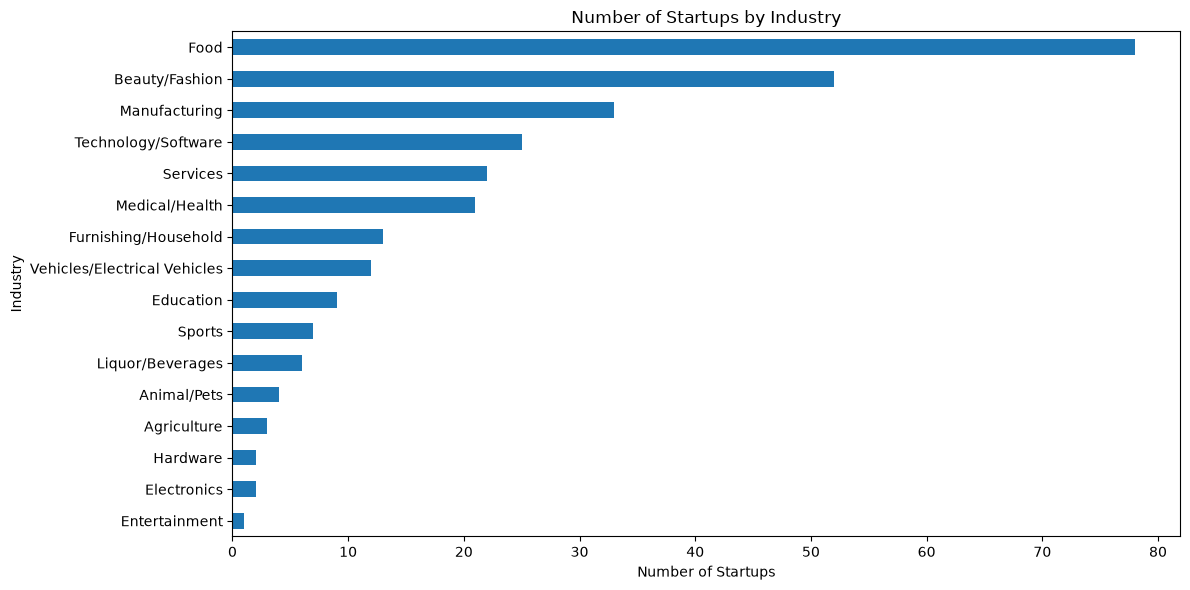

In [9]:
plt.figure(figsize=(12, 6))

industry_counts.sort_values(ascending=True).plot(
    kind="barh"
)

plt.title("Number of Startups by Industry")
plt.xlabel("Number of Startups")
plt.ylabel("Industry")
plt.tight_layout()
plt.show()

In [10]:
# Calculate total investment received by each industry
investment_by_industry = (
    df_clean.groupby("Industry")["Total Deal Amount"]
    .sum()
    .sort_values(ascending=False)
)

print("Total Investment by Industry:")
print(investment_by_industry)

Total Investment by Industry:
Industry
Food                            2457.60005
Beauty/Fashion                  1972.00000
Medical/Health                  1517.00101
Manufacturing                   1081.00000
Services                        1032.00000
Technology/Software              900.00000
Education                        440.00000
Vehicles/Electrical Vehicles     421.00000
Furnishing/Household             225.00000
Sports                           205.00000
Electronics                      200.00000
Entertainment                    150.00000
Liquor/Beverages                 150.00000
Animal/Pets                      110.00000
Agriculture                       60.00000
Hardware                          25.00000
Name: Total Deal Amount, dtype: float64


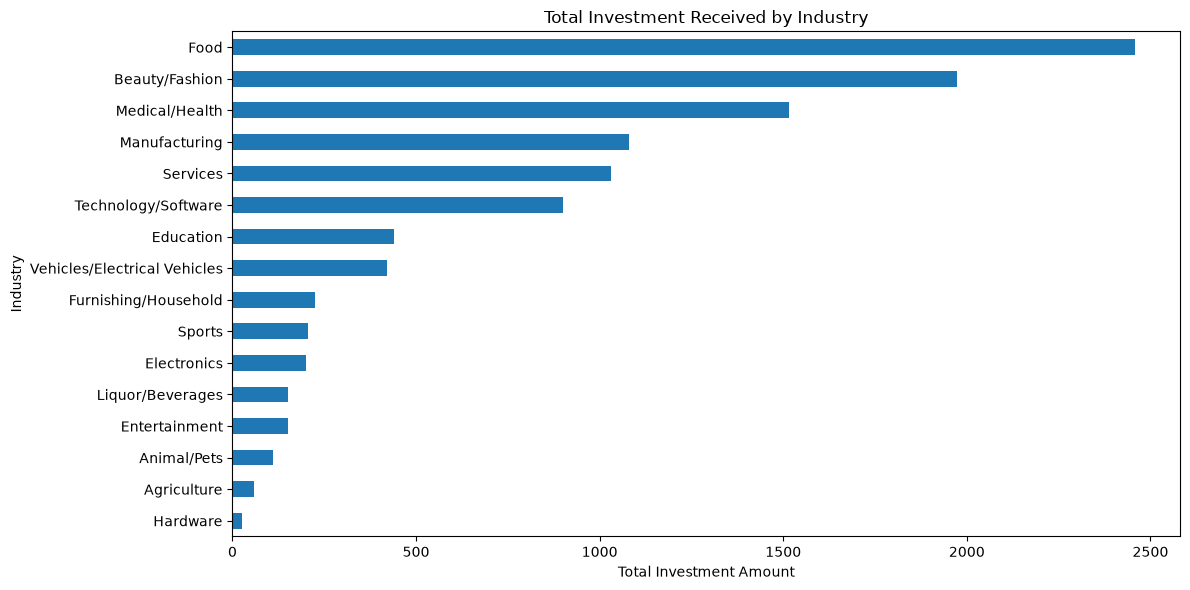

In [11]:
plt.figure(figsize=(12, 6))

investment_by_industry.sort_values(ascending=True).plot(
    kind="barh"
)

plt.title("Total Investment Received by Industry")
plt.xlabel("Total Investment Amount")
plt.ylabel("Industry")
plt.tight_layout()
plt.show()

In [12]:
total_startups = df_clean["Startup Name"].nunique()

total_deals = (df_clean["Accepted Offer"] == 1).sum()

total_investment = df_clean["Total Deal Amount"].sum()

average_deal = df_clean.loc[
    df_clean["Total Deal Amount"] > 0,
    "Total Deal Amount"
].mean()

average_equity = df_clean.loc[
    df_clean["Total Deal Equity"] > 0,
    "Total Deal Equity"
].mean()

print("Total Startups:", total_startups)
print("Total Accepted Deals:", total_deals)
print("Total Investment:", round(total_investment, 2))
print("Average Deal Amount:", round(average_deal, 2))
print("Average Deal Equity:", round(average_equity, 2))

Total Startups: 290
Total Accepted Deals: 175
Total Investment: 10945.6
Average Deal Amount: 62.91
Average Deal Equity: 10.17


In [13]:
sharks = [
    "Ashneer",
    "Namita",
    "Anupam",
    "Vineeta",
    "Aman",
    "Peyush",
    "Ghazal",
    "Amit",
    "Guest"
]

shark_investments = {}

for shark in sharks:
    column = f"{shark} Investment Amount"
    shark_investments[shark] = df_clean[column].sum()

shark_investments = pd.Series(shark_investments).sort_values(
    ascending=False
)

print("Total Investment by Shark:")
print(shark_investments)

Total Investment by Shark:
Aman       2510.040016
Peyush     2180.380252
Namita     2097.510269
Anupam     1451.160268
Vineeta    1170.600000
Amit        800.910000
Ashneer     539.330000
Ghazal      129.990252
Guest        65.500000
dtype: float64


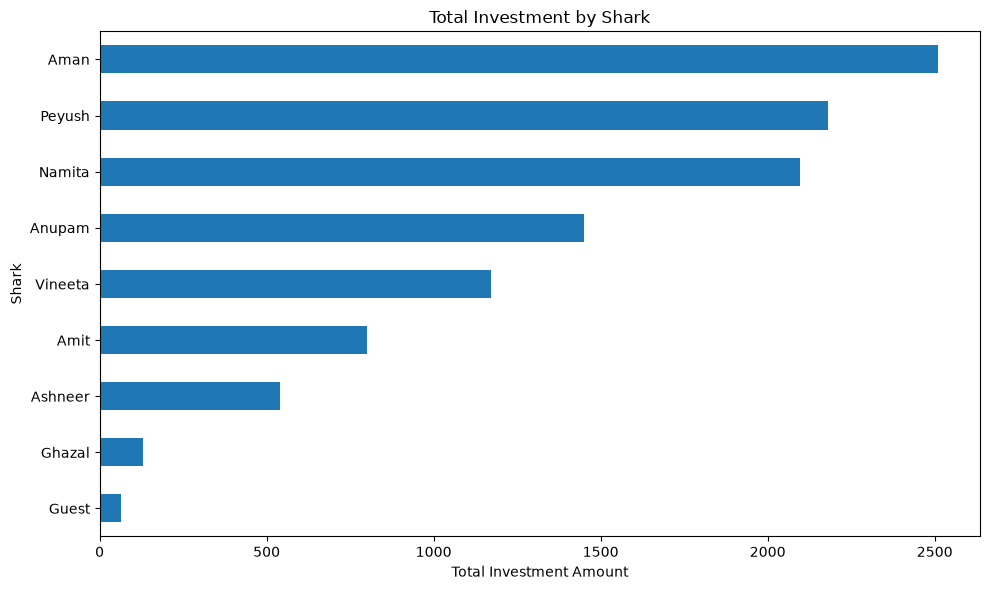

In [14]:
plt.figure(figsize=(10, 6))

shark_investments.sort_values(ascending=True).plot(
    kind="barh"
)

plt.title("Total Investment by Shark")
plt.xlabel("Total Investment Amount")
plt.ylabel("Shark")
plt.tight_layout()
plt.show()

In [15]:
shark_deal_counts = {}

for shark in sharks:
    column = f"{shark} Investment Amount"
    shark_deal_counts[shark] = (df_clean[column] > 0).sum()

shark_deal_counts = pd.Series(shark_deal_counts).sort_values(
    ascending=False
)

print("Number of Deals by Shark:")
print(shark_deal_counts)

Number of Deals by Shark:
Aman       72
Peyush     67
Namita     66
Anupam     50
Vineeta    43
Ashneer    21
Amit       21
Ghazal      7
Guest       2
dtype: int64


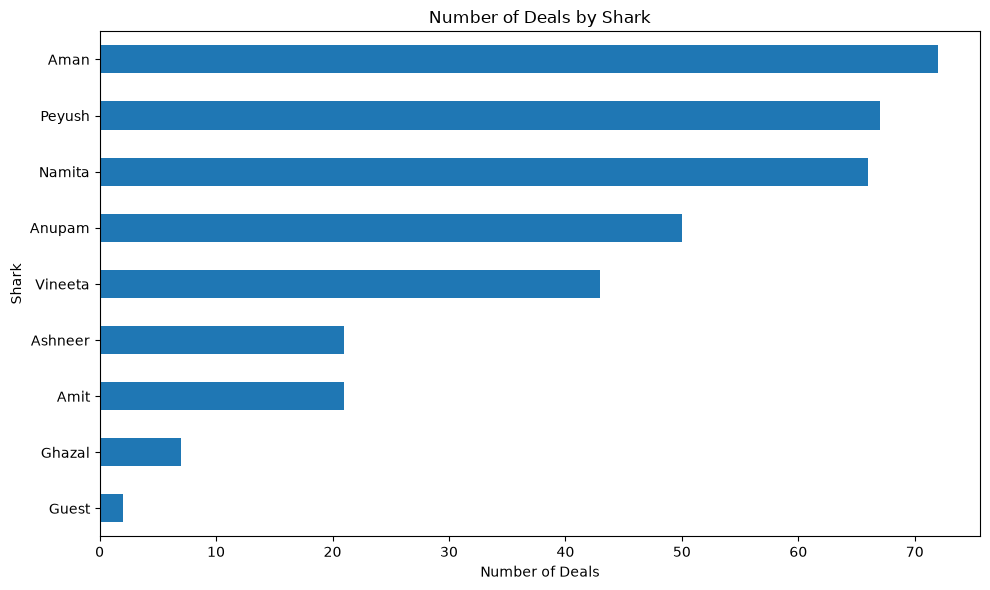

In [16]:
plt.figure(figsize=(10, 6))

shark_deal_counts.sort_values(ascending=True).plot(
    kind="barh"
)

plt.title("Number of Deals by Shark")
plt.xlabel("Number of Deals")
plt.ylabel("Shark")
plt.tight_layout()
plt.show()

In [17]:
offer_counts = df_clean["Accepted Offer"].value_counts()

print("Accepted Offer Distribution:")
print(offer_counts)

Accepted Offer Distribution:
Accepted Offer
1.0    175
0.0    115
Name: count, dtype: int64


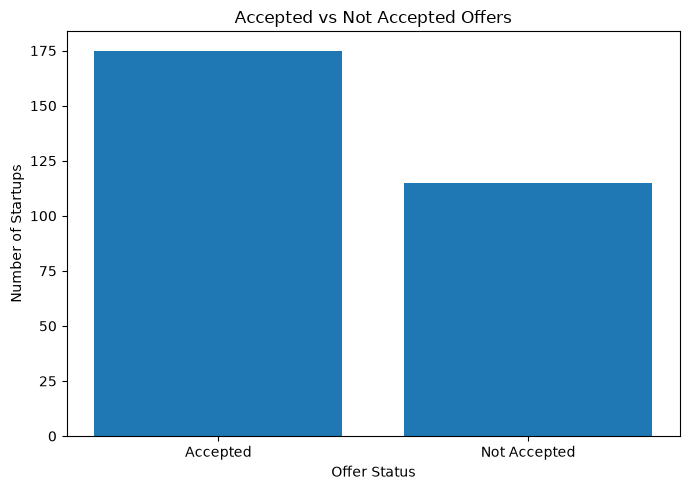

In [18]:
offer_labels = ["Accepted", "Not Accepted"]
offer_values = [175, 115]

plt.figure(figsize=(7, 5))

plt.bar(offer_labels, offer_values)

plt.title("Accepted vs Not Accepted Offers")
plt.xlabel("Offer Status")
plt.ylabel("Number of Startups")
plt.tight_layout()
plt.show()

In [19]:
top_startups = df_clean[
    ["Startup Name", "Industry", "Total Deal Amount"]
].sort_values(
    by="Total Deal Amount",
    ascending=False
).head(10)

print(top_startups.to_string(index=False))

Startup Name            Industry  Total Deal Amount
 Pharmallama      Medical/Health              200.0
      UnStop Technology/Software              200.0
   MeduLance      Medical/Health              200.0
     Trunome      Medical/Health              150.0
       Stage       Entertainment              150.0
      Snitch      Beauty/Fashion              150.0
       Portl            Services              150.0
AasVidyalaya           Education              150.0
   MindPeers      Medical/Health              106.0
       Annie           Education              105.0


In [20]:
ask_vs_deal = df_clean[
    [
        "Startup Name",
        "Industry",
        "Original Ask Amount",
        "Total Deal Amount"
    ]
].copy()

ask_vs_deal["Difference"] = (
    ask_vs_deal["Total Deal Amount"]
    - ask_vs_deal["Original Ask Amount"]
)

print(ask_vs_deal.head(10).to_string(index=False))

    Startup Name                     Industry  Original Ask Amount  Total Deal Amount  Difference
   BluePineFoods                         Food                 50.0               75.0        25.0
    BoozScooters Vehicles/Electrical Vehicles                 40.0               40.0         0.0
HeartUpMySleeves               Beauty/Fashion                 25.0               25.0         0.0
       TagzFoods                         Food                 70.0               70.0         0.0
    HeadAndHeart                    Education                 50.0                0.0       -50.0
     Agritourism                  Agriculture                 50.0                0.0       -50.0
      qZenseLabs                         Food                100.0                0.0      -100.0
       Peeschute               Beauty/Fashion                 75.0               75.0         0.0
            NOCD                         Food                 50.0               20.0       -30.0
           CosIQ    

In [21]:
# Keep only startups that received a deal
successful_deals = df_clean[df_clean["Total Deal Amount"] > 0].copy()

# Calculate overall comparison
total_asked = successful_deals["Original Ask Amount"].sum()
total_received = successful_deals["Total Deal Amount"].sum()

print("Total Amount Asked:", round(total_asked, 2))
print("Total Amount Received:", round(total_received, 2))
print("Difference:", round(total_received - total_asked, 2))

Total Amount Asked: 11831.0
Total Amount Received: 10945.6
Difference: -885.4


In [22]:
# Calculate average deal amount by industry
average_deal_by_industry = (
    successful_deals.groupby("Industry")["Total Deal Amount"]
    .mean()
    .sort_values(ascending=False)
)

print("Average Deal Amount by Industry:")
print(average_deal_by_industry.round(2))

Average Deal Amount by Industry:
Industry
Entertainment                   150.00
Electronics                     100.00
Services                         86.00
Medical/Health                   84.28
Education                        73.33
Technology/Software              64.29
Vehicles/Electrical Vehicles     60.14
Beauty/Fashion                   58.00
Manufacturing                    56.89
Food                             55.85
Animal/Pets                      55.00
Sports                           51.25
Liquor/Beverages                 50.00
Furnishing/Household             45.00
Agriculture                      30.00
Hardware                         25.00
Name: Total Deal Amount, dtype: float64


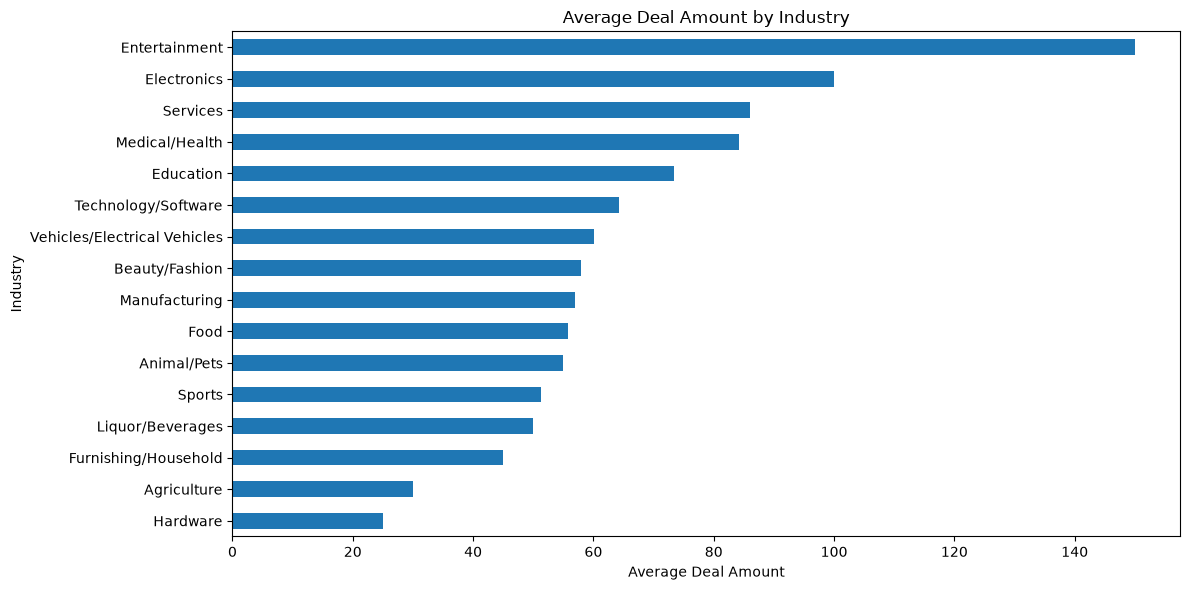

In [23]:
plt.figure(figsize=(12, 6))

average_deal_by_industry.sort_values(ascending=True).plot(
    kind="barh"
)

plt.title("Average Deal Amount by Industry")
plt.xlabel("Average Deal Amount")
plt.ylabel("Industry")
plt.tight_layout()
plt.show()

In [24]:
# Export industry analysis
investment_by_industry.to_csv("investment_by_industry.csv")

# Export shark investment analysis
shark_investments.to_csv("shark_investments.csv")

# Export shark deal counts
shark_deal_counts.to_csv("shark_deal_counts.csv")

# Export average deal by industry
average_deal_by_industry.to_csv("average_deal_by_industry.csv")

# Export top startups
top_startups.to_csv("top_10_funded_startups.csv", index=False)

# Export ask vs deal comparison
ask_vs_deal.to_csv("ask_vs_deal_analysis.csv", index=False)

print("All analysis files exported successfully!")

All analysis files exported successfully!


In [25]:
# Select important columns for Tableau
tableau_data = df_clean[
    [
        "Season Number",
        "Episode Number",
        "Startup Name",
        "Industry",
        "Pitchers Average Age",
        "Pitchers State",
        "Original Ask Amount",
        "Original Offered Equity",
        "Valuation Requested",
        "Received Offer",
        "Accepted Offer",
        "Total Deal Amount",
        "Total Deal Equity",
        "Deal Valuation",
        "Number of sharks in deal"
    ]
].copy()

# Save Tableau-ready dataset
tableau_data.to_csv("tableau_startup_analysis.csv", index=False)

print("Tableau-ready dataset created!")
print("Shape:", tableau_data.shape)

Tableau-ready dataset created!
Shape: (290, 15)
